In [7]:
import pandas as pd 


In [8]:
import numpy as np

In [9]:
import matplotlib.pyplot as plt

In [10]:
import numpy as np
import pandas as pd

# Load the dataset
# 1. parse_dates converts the 'date' column to datetime objects
# 2. dtype={'stn': str, 'wban': str} keeps station IDs formatted with leading zeros
df = pd.read_csv(
    "noaa - 5000.csv",
    parse_dates=["date"],
    dtype={"stn": str, "wban": str}
)

# Display basic information and first 5 rows
print(f"Dataset shape: {df.shape}")
df.head()


Dataset shape: (5000, 33)


,stn,wban,date,year,mo,da,temp,count_temp,dewp,count_dewp,...,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
0,010020,99999,2025-07-04,2025,7,4,42.1,4,38.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
1,010020,99999,2025-04-30,2025,4,30,7.6,4,3.8,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
2,010020,99999,2025-04-19,2025,4,19,2.7,4,-2.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
3,010020,99999,2025-04-20,2025,4,20,4.2,4,-1.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
4,010020,99999,2025-03-05,2025,3,5,14.4,4,10.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0


In [11]:
# Replace NOAA missing value sentinel flags with NaN
missing_flags = [999.9, 9999.9]
cols_to_clean = ["temp", "dewp", "slp", "stp", "visib", "wdsp", "mxpsd", "gust", "max", "min", "sndp"]

for col in cols_to_clean:
    if col in df.columns:
        df[col] = df[col].replace(missing_flags, np.nan)

# Check summary statistics after cleaning
df[["temp", "dewp", "slp", "wdsp", "prcp"]].describe()


,temp,dewp,slp,wdsp,prcp
count,5000.000000,4765.000000,3443.000000,4709.000000,5000.000000
mean,59.977860,49.015446,1010.695295,4.796178,3.642022
std,29.405094,26.778858,10.304839,5.153405,18.464065
min,-105.300000,-116.100000,951.200000,0.000000,0.000000
25%,45.800000,35.600000,1005.500000,1.600000,0.000000
50%,68.300000,54.300000,1010.200000,3.400000,0.000000
75%,81.700000,70.200000,1015.300000,6.200000,0.020000
max,109.400000,84.700000,1055.600000,64.100000,99.990000


In [12]:
# Sort values chronologically
df = df.sort_values(by="date")

# Set date as index
df_ts = df.set_index("date")
df_ts.head()


,stn,wban,year,mo,da,temp,count_temp,dewp,count_dewp,slp,...,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
date,,,,,,,,,,,,,,,,,,,,,
2025-01-01,242610,99999,2025,1,1,-28.6,5,-36.0,5,1019.7,...,*,0.03,E,NaN,0,0,1,0,0,0
2025-01-01,422990,99999,2025,1,1,53.0,4,43.5,4,NaN,...,NaN,0.00,I,NaN,0,0,0,0,0,0
2025-01-01,431110,99999,2025,1,1,69.4,4,56.5,4,NaN,...,NaN,0.00,I,NaN,0,0,0,0,0,0
2025-01-01,679690,99999,2025,1,1,82.7,4,NaN,0,NaN,...,NaN,0.00,G,NaN,0,1,0,0,1,0
2025-01-01,432780,99999,2025,1,1,79.7,5,74.9,5,1013.9,...,NaN,0.00,I,NaN,0,0,0,0,0,0


In [13]:
date_index = pd.date_range(start='2025-01-01', periods=365, freq='D')
date_index


DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04',
               '2025-01-05', '2025-01-06', '2025-01-07', '2025-01-08',
               '2025-01-09', '2025-01-10',
               ...
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-25',
               '2025-12-26', '2025-12-27', '2025-12-28', '2025-12-29',
               '2025-12-30', '2025-12-31'],
              dtype='datetime64[ns]', length=365, freq='D')

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load the dataset
df = pd.read_csv("noaa - 5000.csv")

# 2. Convert the 'date' column into official Pandas Timestamp objects
df["date"] = pd.to_datetime(df["date"])

# Preview the data types and first few rows
print(df[["date", "temp"]].head())

        date  temp
0 2025-07-04  42.1
1 2025-04-30   7.6
2 2025-04-19   2.7
3 2025-04-20   4.2
4 2025-03-05  14.4


In [15]:
# 1. Set the date column as the index
df = df.set_index("date")

# 2. Sort the index chronologically to ensure proper time alignment
df = df.sort_index()

# 3. Demonstrate date-based slicing (e.g., viewing data for July 2025)
july_data = df.loc["2025-07"]
print(f"Number of readings in July 2025: {len(july_data)}")

# Optional: Generate a continuous date range to check for any missing dates
full_range = pd.date_range(
    start=df.index.min(), end=df.index.max(), freq="D"
)
print(f"Total expected days in range: {len(full_range)}")
print(f"Actual rows in dataset: {len(df)}")

Number of readings in July 2025: 710
Total expected days in range: 240
Actual rows in dataset: 5000


In [16]:
# 1. Resample daily temperature ('temp') to monthly average ('M')
monthly_temp = df["temp"].resample("M").mean()

# 2. Resample daily temperature to weekly average ('W')
weekly_temp = df["temp"].resample("W").mean()

# Display the first few rows of the resampled monthly data
print("Monthly Average Temperatures:")
print(monthly_temp.head())

Monthly Average Temperatures:
date
2025-01-31    45.653073
2025-02-28    47.156707
2025-03-31    54.819702
2025-04-30    61.089535
2025-05-31    66.567719
Freq: ME, Name: temp, dtype: float64


C:\Users\HP\AppData\Local\Temp\ipykernel_25576\2087399635.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_temp = df["temp"].resample("M").mean()


In [17]:
# 1. Calculate a 30-day rolling window mean on the daily temperature
df["temp_rolling_30d"] = df["temp"].rolling(window=30).mean()

# Preview the rolling average column alongside the raw temperature
print(df[["temp", "temp_rolling_30d"]].tail(10))

            temp  temp_rolling_30d
date                              
2025-08-27  71.3         71.706667
2025-08-27  59.8         71.576667
2025-08-27  46.3         70.390000
2025-08-27  69.7         69.906667
2025-08-27  56.7         69.096667
2025-08-27  56.3         68.130000
2025-08-27  53.2         67.846667
2025-08-27  64.3         67.213333
2025-08-27  62.0         66.606667
2025-08-28  57.2         65.920000


In [18]:
# 1. Extract calendar attributes directly from the index
df["month"] = df.index.month
df["day_name"] = df.index.day_name()

# 2. Group by month to find the average temperature for each calendar month
monthly_climate_pattern = df.groupby("month")["temp"].mean()

print("Average Temperature by Month:")
print(monthly_climate_pattern)

Average Temperature by Month:
month
1    45.653073
2    47.156707
3    54.819702
4    61.089535
5    66.567719
6    67.142985
7    70.449718
8    68.461036
Name: temp, dtype: float64


c:\Users\HP\anaconda3\Lib\site-packages\pandas\plotting\_matplotlib\core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


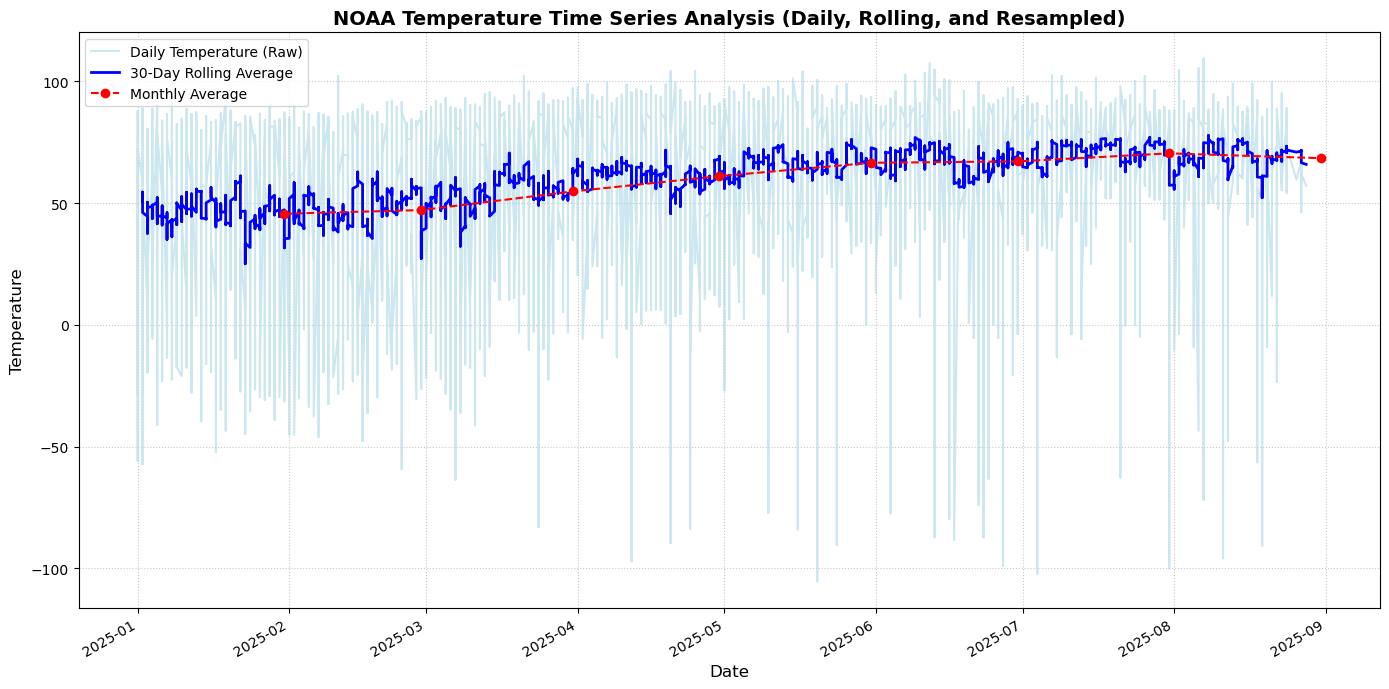

In [19]:
# Set up the plot size
plt.figure(figsize=(14, 7))

# 1. Plot raw daily readings (using a light alpha for transparency)
plt.plot(
    df.index,
    df["temp"],
    label="Daily Temperature (Raw)",
    color="lightblue",
    alpha=0.6,
)

# 2. Plot the 30-day rolling average
plt.plot(
    df.index,
    df["temp_rolling_30d"],
    label="30-Day Rolling Average",
    color="blue",
    linewidth=2,
)

# 3. Plot the monthly resampled points
monthly_temp.plot(
    label="Monthly Average", color="red", marker="o", linestyle="--"
)

# Add title, labels, legend, and grid for readability
plt.title(
    "NOAA Temperature Time Series Analysis (Daily, Rolling, and Resampled)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Temperature", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.7)

# Display the chart
plt.tight_layout()
plt.show()